Mounted at /content/drive
=== KẾT QUẢ KIỂM TRA HỢP LỆ (MỤC 4.1) ===
 - 01_DecisionTree (Decision Tree): ĐẠT
 - 02_kNN (kNN): ĐẠT
 - 03_SVM (SVM (RBF)): ĐẠT
 - 04_MLP (MLP): ĐẠT
 - 05_Logistic (Logistic Regression): ĐẠT


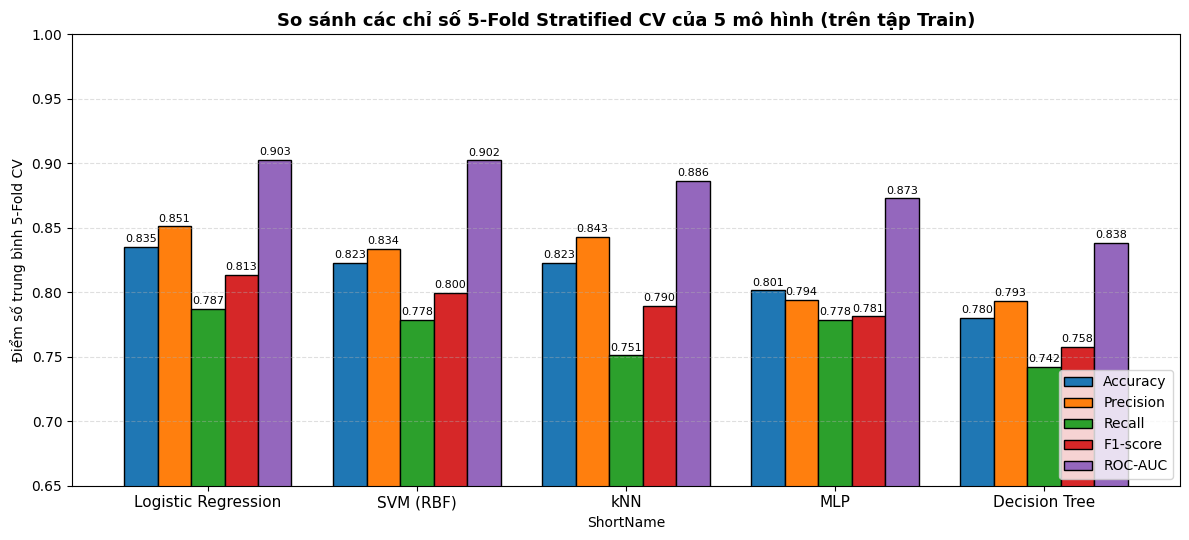

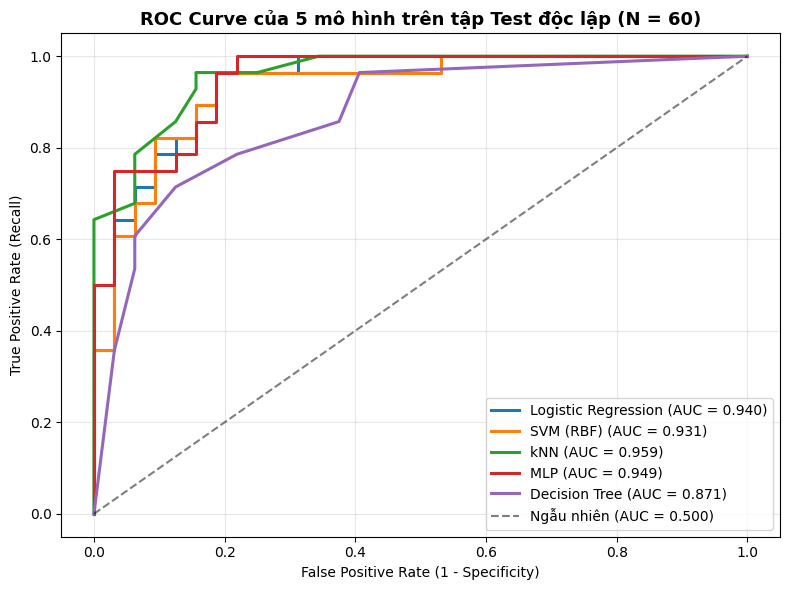

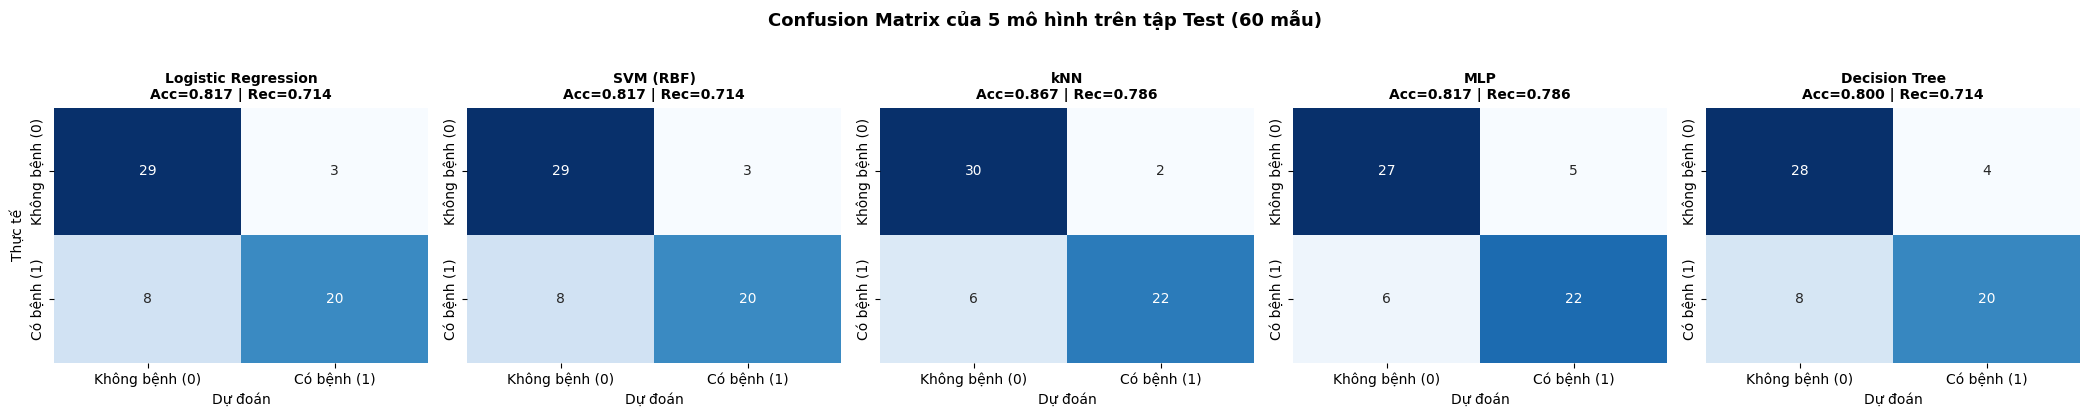

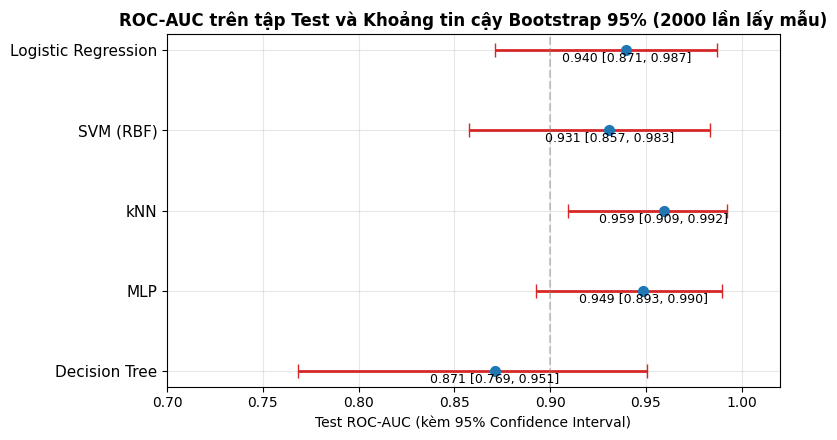


=== BẢNG 2 (5-FOLD CV TRÊN TẬP TRAIN - XẾP THEO ROC-AUC, LÀM TRÒN 3 CHỮ SỐ) ===
Logistic Regression                 | Acc: 0.835 ± 0.080 | Prec: 0.851 | Rec: 0.787 | F1: 0.813 | ROC-AUC: 0.903
SVM (RBF, C=10, γ=0.01)             | Acc: 0.823 ± 0.072 | Prec: 0.834 | Rec: 0.778 | F1: 0.800 | ROC-AUC: 0.902
kNN (k=17, Manhattan)               | Acc: 0.823 ± 0.067 | Prec: 0.843 | Rec: 0.751 | F1: 0.790 | ROC-AUC: 0.886
MLP (16, tanh, α=0.1)               | Acc: 0.801 ± 0.066 | Prec: 0.794 | Rec: 0.778 | F1: 0.781 | ROC-AUC: 0.873
Decision Tree (depth=3, leaf=10)    | Acc: 0.780 ± 0.099 | Prec: 0.793 | Rec: 0.742 | F1: 0.758 | ROC-AUC: 0.838

=== BẢNG 3 (KẾT QUẢ TRÊN TẬP TEST - LÀM TRÒN 3 CHỮ SỐ) ===
Logistic Regression    | Acc: 0.817 | Prec: 0.870 | Rec: 0.714 | F1: 0.784 | ROC-AUC: 0.940
SVM (RBF)              | Acc: 0.817 | Prec: 0.870 | Rec: 0.714 | F1: 0.784 | ROC-AUC: 0.931
kNN                    | Acc: 0.867 | Prec: 0.917 | Rec: 0.786 | F1: 0.846 | ROC-AUC: 0.959
MLP               

In [1]:
from google.colab import drive
import os, glob, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# 1. MOUNT DRIVE & ĐỊNH VỊ THƯ MỤC
drive.mount('/content/drive')
possible_paths = glob.glob('/content/drive/**/BTL_46_Heart_Disease', recursive=True)
BASE_DIR  = possible_paths[0]
DATA_DIR  = os.path.join(BASE_DIR, "00_Shared/data")
FINAL_DIR = os.path.join(BASE_DIR, "06_Final_Comparison")
os.makedirs(FINAL_DIR, exist_ok=True)

y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

# 2. TỰ ĐỘNG GIẢI NÉN FILE ZIP KẾT QUẢ (NẾU CÓ, VÍ DỤ results_kNN.zip CỦA TV2)
for folder_name in ["01_DecisionTree", "02_kNN", "03_SVM", "04_MLP", "05_Logistic"]:
    f_path = os.path.join(BASE_DIR, folder_name)
    for zf in glob.glob(os.path.join(f_path, "*.zip")):
        if "data.zip" not in os.path.basename(zf):
            extract_to = os.path.join(f_path, "unzipped_results")
            if not os.path.exists(extract_to):
                with zipfile.ZipFile(zf, 'r') as zip_ref:
                    zip_ref.extractall(extract_to)
                print(f"Đã giải nén {zf} -> {extract_to}")

# 3. THU THẬP & KIỂM TRA TÍNH HỢP LỆ THEO CONTRACT (MỤC 4.1)
member_configs = [
    ("Decision Tree",       "01_DecisionTree", "Decision Tree (depth=3, leaf=10)"),
    ("kNN",                 "02_kNN",          "kNN (k=17, Manhattan)"),
    ("SVM (RBF)",           "03_SVM",          "SVM (RBF, C=10, γ=0.01)"),
    ("MLP",                 "04_MLP",          "MLP (16, tanh, α=0.1)"),
    ("Logistic Regression", "05_Logistic",     "Logistic Regression")
]

required_keys = ["Model", "Accuracy_mean", "Accuracy_std", "Precision_mean", "Recall_mean", "F1_mean", "ROC_AUC_mean", "Best_params", "Note"]
cv_rows = []
test_rows = []
preds_map = {}
scores_map = {}
validation_logs = []

for short_name, folder, display_label in member_configs:
    folder_path = os.path.join(BASE_DIR, folder)
    jsons  = [p for p in glob.glob(os.path.join(folder_path, "**/*.json"), recursive=True) if "checkpoint" not in p]
    preds  = [p for p in glob.glob(os.path.join(folder_path, "**/*pred*.npy"), recursive=True)]
    scores = [p for p in glob.glob(os.path.join(folder_path, "**/*score*.npy"), recursive=True)]

    if jsons and preds and scores:
        with open(jsons[0], "r", encoding="utf-8") as f:
            d = json.load(f)
        y_p = np.load(preds[0]).ravel()
        y_s = np.load(scores[0]).ravel()

        # Kiểm tra hợp lệ theo Mục 4.1
        missing_k = [k for k in required_keys if k not in d]
        valid_len = (len(y_p) == 60 and len(y_s) == 60)
        valid_bin = set(np.unique(y_p)).issubset({0, 1})
        status = "ĐẠT" if (not missing_k and valid_len and valid_bin) else f"LỖI ({missing_k}, len={len(y_p)})"
        validation_logs.append(f"{folder} ({short_name}): {status}")

        d["ShortName"] = short_name
        d["DisplayLabel"] = display_label
        cv_rows.append(d)

        preds_map[short_name]  = y_p
        scores_map[short_name] = y_s

        test_rows.append({
            "Model": short_name,
            "Accuracy":  accuracy_score(y_test, y_p),
            "Precision": precision_score(y_test, y_p),
            "Recall":    recall_score(y_test, y_p),
            "F1":        f1_score(y_test, y_p),
            "ROC_AUC":   roc_auc_score(y_test, y_s)
        })
    else:
        validation_logs.append(f"{folder} ({short_name}): THIẾU FILE TRÊN DRIVE (json={len(jsons)}, pred={len(preds)}, score={len(scores)})")

print("=== KẾT QUẢ KIỂM TRA HỢP LỆ (MỤC 4.1) ===")
for log in validation_logs:
    print(" -", log)

df_cv   = pd.DataFrame(cv_rows).sort_values(by="ROC_AUC_mean", ascending=False).reset_index(drop=True)
df_test = pd.DataFrame(test_rows)
# Sắp xếp Bảng 3 theo thứ tự của Bảng 2 (hoặc theo ROC_AUC)
df_test = df_test.set_index("Model").loc[df_cv["ShortName"]].reset_index()

df_cv.to_csv(os.path.join(FINAL_DIR, "comparison_cv.csv"), index=False)
df_test.to_csv(os.path.join(FINAL_DIR, "comparison_test.csv"), index=False)

# 4. VẼ HÌNH 4: Compare_CV_metrics.png
metrics_cols = ["Accuracy_mean", "Precision_mean", "Recall_mean", "F1_mean", "ROC_AUC_mean"]
plot_df = df_cv.set_index("ShortName")[metrics_cols]
ax = plot_df.plot(kind="bar", figsize=(12, 5.5), width=0.8, edgecolor="black")
plt.title("So sánh các chỉ số 5-Fold Stratified CV của 5 mô hình (trên tập Train)", fontweight="bold", fontsize=13)
plt.ylabel("Điểm số trung bình 5-Fold CV")
plt.ylim(0.65, 1.0)
plt.xticks(rotation=0, fontsize=11)
plt.legend(["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"], loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "Compare_CV_metrics.png"), dpi=300)
plt.show()

# 5. VẼ HÌNH 5: Compare_ROC_test.png
plt.figure(figsize=(8, 6))
for name in df_cv["ShortName"]:
    y_s = scores_map[name]
    fpr, tpr, _ = roc_curve(y_test, y_s)
    auc_v = roc_auc_score(y_test, y_s)
    plt.plot(fpr, tpr, lw=2.2, label=f"{name} (AUC = {auc_v:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Ngẫu nhiên (AUC = 0.500)")
plt.title("ROC Curve của 5 mô hình trên tập Test độc lập (N = 60)", fontweight="bold", fontsize=13)
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "Compare_ROC_test.png"), dpi=300)
plt.show()

# 6. VẼ HÌNH 6: Compare_ConfusionMatrix_test.png
n_models = len(df_cv)
fig, axes = plt.subplots(1, n_models, figsize=(4.2 * n_models, 4))
if n_models == 1: axes = [axes]
for idx, name in enumerate(df_cv["ShortName"]):
    cm = confusion_matrix(y_test, preds_map[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["Không bệnh (0)", "Có bệnh (1)"],
                yticklabels=["Không bệnh (0)", "Có bệnh (1)"])
    acc_v = accuracy_score(y_test, preds_map[name])
    rec_v = recall_score(y_test, preds_map[name])
    axes[idx].set_title(f"{name}\nAcc={acc_v:.3f} | Rec={rec_v:.3f}", fontweight="bold", fontsize=10)
    axes[idx].set_xlabel("Dự đoán")
    if idx == 0:
        axes[idx].set_ylabel("Thực tế")
    else:
        axes[idx].set_ylabel("")
plt.suptitle("Confusion Matrix của 5 mô hình trên tập Test (60 mẫu)", fontweight="bold", fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "Compare_ConfusionMatrix_test.png"), dpi=300, bbox_inches="tight")
plt.show()

# 7. VẼ HÌNH 7: Compare_AUC_bootstrap_CI.png (Bootstrap 95% CI trên tập Test)
rng = np.random.RandomState(42)
n_boot = 2000
ci_rows = []
for name in df_cv["ShortName"]:
    y_s = scores_map[name]
    boot_aucs = []
    for _ in range(n_boot):
        indices = rng.randint(0, len(y_test), len(y_test))
        if len(np.unique(y_test[indices])) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_test[indices], y_s[indices]))
    low, high = np.percentile(boot_aucs, [2.5, 97.5])
    point_auc = roc_auc_score(y_test, y_s)
    ci_rows.append({
        "Model": name, "AUC": point_auc, "CI_low": low, "CI_high": high, "Width": high - low
    })
df_ci = pd.DataFrame(ci_rows)

plt.figure(figsize=(8, 4.5))
y_pos = np.arange(len(df_ci))
plt.errorbar(df_ci["AUC"], y_pos,
             xerr=[df_ci["AUC"] - df_ci["CI_low"], df_ci["CI_high"] - df_ci["AUC"]],
             fmt="o", color="#1f77b4", ecolor="#d62728", elinewidth=2, capsize=5, markersize=7)
plt.yticks(y_pos, df_ci["Model"], fontsize=11)
for i, r in df_ci.iterrows():
    plt.text(r["AUC"], i + 0.15, f"{r['AUC']:.3f} [{r['CI_low']:.3f}, {r['CI_high']:.3f}]", ha="center", fontsize=9)
plt.xlim(0.70, 1.02)
plt.axvline(0.90, color="gray", linestyle="--", alpha=0.4)
plt.title("ROC-AUC trên tập Test và Khoảng tin cậy Bootstrap 95% (2000 lần lấy mẫu)", fontweight="bold")
plt.xlabel("Test ROC-AUC (kèm 95% Confidence Interval)")
plt.grid(True, alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "Compare_AUC_bootstrap_CI.png"), dpi=300)
plt.show()

# 8. IN BẢNG 2, BẢNG 3 VÀ KHOẢNG TIN CẬY ĐỂ ĐIỀN VÀO MỤC 4 FILE WORD
print("\n=== BẢNG 2 (5-FOLD CV TRÊN TẬP TRAIN - XẾP THEO ROC-AUC, LÀM TRÒN 3 CHỮ SỐ) ===")
for _, r in df_cv.iterrows():
    print(f"{r['DisplayLabel']:35s} | Acc: {r['Accuracy_mean']:.3f} ± {r['Accuracy_std']:.3f} | Prec: {r['Precision_mean']:.3f} | Rec: {r['Recall_mean']:.3f} | F1: {r['F1_mean']:.3f} | ROC-AUC: {r['ROC_AUC_mean']:.3f}")

print("\n=== BẢNG 3 (KẾT QUẢ TRÊN TẬP TEST - LÀM TRÒN 3 CHỮ SỐ) ===")
for _, r in df_test.iterrows():
    print(f"{r['Model']:22s} | Acc: {r['Accuracy']:.3f} | Prec: {r['Precision']:.3f} | Rec: {r['Recall']:.3f} | F1: {r['F1']:.3f} | ROC-AUC: {r['ROC_AUC']:.3f}")

widest = df_ci.sort_values(by="Width", ascending=False).iloc[0]
narrowest = df_ci.sort_values(by="Width", ascending=True).iloc[0]
print(f"\n=== Ô [[điền khoảng rộng nhất/hẹp nhất]] Ở HÌNH 7 ===")
print(f"Rộng nhất là {widest['Model']}: [{widest['CI_low']:.3f}, {widest['CI_high']:.3f}] (độ rộng {widest['Width']:.3f}); hẹp nhất là {narrowest['Model']}: [{narrowest['CI_low']:.3f}, {narrowest['CI_high']:.3f}] (độ rộng {narrowest['Width']:.3f}).")